# 01. Analisi esplorativa dei dati (EDA)

**Progetto:** HelpDesk AI **Passo 1:** Dati

Lo scopo di questo notebook è quello di "conoscere" i dati prima di qualsisasi addestramento (valori mancanti, duplicati, etichettte sbagliate ecc.).

## Cosa faremo:
1. Importare le librerie
2. Impostare la configurazione (percorsi, nomi delle colonne, stile dei grafici)
3. Caricare il dataset
4. Fare una prima ispezione dei dati
5. Controllare la qualità (valori mancanti, testi vuoti, ecc.)
6. Studiare la distribuzione delle categorie
7. Studiare la lunghezza dei ticket
8. Studiare il vocabolario e le parole caratteristiche di ogni categoria
9. Leggere esempi reali per ogni categoria
10. Riepilogo

## 1. Importare le librerie

| Libreria | A cosa serve qui |
|---|---|
| `pathlib` | gestire i percorsi dei file in modo che funzionino su Windows, macOS e Linux |
| `collections.Counter` | contare le parole in modo semplice e veloce |
| `numpy` | calcoli numerici su array |
| `pandas` | caricare e analizzare la tabella dei ticket (DataFrame) |
| `matplotlib` | disegnare i grafici |
| `seaborn` | grafici statistici (es. boxplot) con meno codice, sopra matplotlib |
| `scikit-learn` | qui solo per TF-IDF e per l'elenco delle stopword inglesi |

In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

## 2. Configurazione

Mettiamo **in un solo posto** tutto ciò che potrebbe cambiare: percorsi, nomi delle colonne, colori. Se un domani il file avesse un nome diverso, modifichi una riga qui e non dieci righe sparse nel notebook.

In [2]:
# --- Riproducibilità ---
RANDOM_STATE = 42

# --- Percorsi ---
PROJECT_DIR = Path("..")
DATA_PATH = PROJECT_DIR / "data" / "raw" / "all_tickets_processed_improved_v3.csv"

# --- Colonne del dataset ---
TEXT_COL = "Document" # Testo del ticket
LABEL_COL = "Topic_group" # Categoria (etichetta)

# --- Stile dei grafici ---
COLORE = "#2a78d6"            # colore unico per le barre
COLORE_CHIARO = "#a9c8ee"     # versione chiara per i box dei boxplot
TESTO = "#0b0b0b"
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": GRIGLIA,
    "axes.labelcolor": TESTO_SECONDARIO,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,   # la griglia resta dietro le barre
    "grid.color": GRIGLIA,
    "grid.linewidth": 0.8,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
    "text.color": TESTO,
})

# Mostra testi lunghi senza tagliarli troppo nelle tabelle
pd.set_option("display.max_colwidth", 200)

# --- Controllo ---
print("Cerco il dataset in:", DATA_PATH.resolve())
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "File non trovato. Scarica il dataset da Kaggle, estrai lo zip e copia"
        "'all_ticket_processed_improved_v3.csv' nella carella data/raw/ del progetto."
    )
print("Trovato!")

Cerco il dataset in: C:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Capstone_Project\data\raw\all_tickets_processed_improved_v3.csv
Trovato!


# 3. Caricare il dataset
Usiamo `pd.read_csv` per leggere il CSV e trasformarlo in un DataFrame con righe (i ticket) e colonne (testo e categoria).

In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Righe (ticket): {df.shape[0]:,}".replace(",","."))
print(f"Colonne: {df.shape[1]}")

Righe (ticket): 47.837
Colonne: 2


# 4. Prima ispezione
- `df.info()` mostra i nomi delle colonne, il tipo di dato e quanti valori non mancanti ci sono.
- `df.sample(...)` mostra righe casuali. Usiamo `sample` invece di `head` perché, se il file fosse ordinato per categoria, head ci mostrerebbe solo le prime righe che corrisponderebbero a ticket della stessa categoria e ci darebbe un'idea sbagliata.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Document     47837 non-null  str  
 1   Topic_group  47837 non-null  str  
dtypes: str(2)
memory usage: 747.6 KB


In [5]:
df.sample(8, random_state=RANDOM_STATE)

,Document,Topic_group
41946,issue with server process sent tuesday issue with server process hi could you please help with following issue getting once few minutes discipline lead,Hardware
20882,new purchase po wednesday february purchase po dear purchased please log installation please take consideration mandatory receipts section order receive item ordered kind regards administrator inf...,Purchase
37017,oracle pas urgent re we updated rights query hi can get some assistance here looks like have full control for codes only one working for cannot forecast need done by friday thanks programme portfo...,Hardware
29138,new starter access thursday pm re starter form hello please find attached employees added comments needs each person profile please take consideration urgent next october thank help regards leader...,HR Support
9536,new phone phone hi taken work mobile phone speak everything thanks,Hardware
12859,confluence account confluence hello please create confluence thank,Access
42362,web not working on hello we changed configuration for documents be client app web app we shut down web app apologize for misunderstanding try using explorer when opening documents web we could go ...,Hardware
33079,new project setup oracle july pm setup hi please per attached setup form please let questions thanks director,Internal Project


# 5. Qualità dei dati

Cerchiamo quattro problemi, ognuno con una conseguenza precisa:

| Problema | Perché ci interessa |
|---|---|
| **Valori mancanti** (`NaN`) | molte funzioni danno errore o ignorano la riga senza avvisare |
| **Testi vuoti** (solo spazi) | un ticket senza testo non insegna nulla al modello |
| **Duplicati** | se lo stesso ticket finisce sia nei dati di addestramento sia in quelli di test, il modello "lo ha già visto" e le metriche risultano **migliori del vero** (*data leakage*) |
| **Etichette in conflitto** (stesso testo, categorie diverse) | il modello riceve segnali contraddittori: è rumore nelle etichette |

In [6]:
# 1. Valori mancanti per colonna
print("Valori mancanti per colonna:")
print(df.isna().sum().to_string())

# 2. Testi vuoti o composti da soli spazi
testo = df[TEXT_COL].fillna("")
n_vuoti = testo.str.strip().eq("").sum()
print(f"\nTesti vuoti o solo spazi: {n_vuoti}")

# 3. Duplicati
n_dup_righe = df.duplicated().sum()                     # righe identiche (testo + categoria)
n_dup_testo = df.duplicated(subset=[TEXT_COL]).sum()    # stesso testo, categoria qualsiasi
print(f"Righe duplicate identiche:  {n_dup_righe}")
print(f"Testi duplicati:            {n_dup_testo}")

# 4. Etichette in conflitto: lo stesso testo compare in più di una categoria
categorie_per_testo = df.groupby(TEXT_COL)[LABEL_COL].nunique()
n_conflitti = (categorie_per_testo > 1).sum()
print(f"Testi con categorie diverse: {n_conflitti}")

# 5. Valori distinti della categoria (controlliamo anceh spazi o maiuscole)
print("\nCategorie presenti:")
print(sorted(df[LABEL_COL].dropna().unique()))


Valori mancanti per colonna:
Document       0
Topic_group    0

Testi vuoti o solo spazi: 0
Righe duplicate identiche:  0
Testi duplicati:            0
Testi con categorie diverse: 0

Categorie presenti:
['Access', 'Administrative rights', 'HR Support', 'Hardware', 'Internal Project', 'Miscellaneous', 'Purchase', 'Storage']


Il dataset è pulito e non sarà necessaria nessuna azione di pulizia. Se avessimo avuto valori su cui intervenire sarebbe stato necessario farlo prima di dividere i dati in *train* e *test*.
- Testo mancante o vuoto --> si elimina la riga perché i valori mancanti non si possono imputare con media\mediana essendo testo e non numeri.
- Categoria mancante --> si toglie dall'addestramento perché non è utile ad addestrare il modello.
- Righe duplicate --> se ne tiene solamente una per evitare il *data leakage*.
- Stesso testo con categorie diverse --> se sono pochi casi andrebbero valutati, se sono molti andrebbe valutata e tenuta la categoria più frequente ed eliminati i casi in parità, in alternativa andrebbero eliminate tutte le copie in conflitto perdendo però qualche dato.
- Categorie scritte in modo diverso --> andrebbero normalizzati per evitare che il modello le tratti come categorie distinte.


# 6. Distribuzione delle categorie
**L'accuratezza** da sola inganna perché, se una categoria contiene il 28% dei ticket, un modello che risponde sempre quella categoria ha già un 28% di accuratezza senza aver imparato nulla. Se invece il modello sbagliasse tutti i ticket di una categoria piccola l'accuratezza scenderebbe pochissimo ed il problema non sarebbe visibile.

**Cosa faremo:**
1. `Metrica: F1 macro` -> Calcola l'F1 per ogni categoria e poi fa la media dando a tutte lo stesso peso.
2. `Split stratificato` -> train, validation e test avranno le stesse proporzioni di categorie del dataset completo.
3. `class_weight="balanced"` -> durante l'addestramento gli errori sulle categorie piccole pesano di più.

In [7]:
conteggi = df[LABEL_COL].value_counts()
percentuali = df[LABEL_COL].value_counts(normalize=True) * 100

tabella_classi = pd.DataFrame({
    "ticket": conteggi,
    "percentuale (%)": percentuali.round(1),
})
display(tabella_classi)

rapporto = conteggi.max() / conteggi.min()
print(f"Rapporto tra categoria più grande e più piccola: {rapporto:.1f} a 1")

,ticket,percentuale (%)
Topic_group,,
Hardware,13617,28.5
HR Support,10915,22.8
Access,7125,14.9
Miscellaneous,7060,14.8
Storage,2777,5.8
Purchase,2464,5.2
Internal Project,2119,4.4
Administrative rights,1760,3.7


Rapporto tra categoria più grande e più piccola: 7.7 a 1


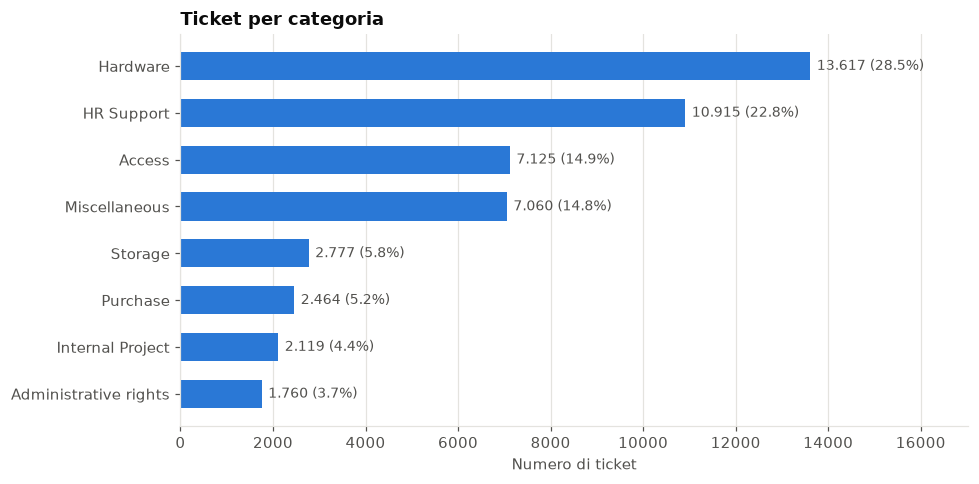

In [8]:
# Grafico a barre orizzontali ed ordinato dal più piccolo al più grande
ordine = conteggi.sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(ordine.index, ordine.values, color=COLORE, height=0.6)

# Etichetta con numero e percentuale accanto ad ogni barra
for posizione, (categoria, valore) in enumerate(ordine.items()):
    etichetta = f"{valore:,}".replace(",",".") + f" ({percentuali[categoria]:.1f}%)"
    ax.text(valore + ordine.max() * 0.01, posizione, etichetta, va="center", fontsize=9, color=TESTO_SECONDARIO)

ax.set_title("Ticket per categoria")
ax.set_xlabel("Numero di ticket")
ax.set_xlim(0, ordine.max() * 1.25) # Spazio a destra per le etichette
ax.grid(axis="y", visible=False)    # Solo griglia verticale
plt.tight_layout()
plt.show()

# 7. Lunghezza dei ticket
Contiamo le palore di ogni ticket. Ci serve per la rete LSTM che vuole lunghezze fisse: i ticket più corti vengono allungati con zeri [padding] e quelli più lunghi vengono tagliati [truncation], sceglieremo la lunghezza guardando i percentili.


In [9]:
df["n_parole"] = testo.str.split().str.len()

# describe con i percentili
display(df["n_parole"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).round(1).to_frame("parole per ticket"))

mediana = df["n_parole"].median()
p95 = df["n_parole"].quantile(0.95)
p99 = df["n_parole"].quantile(0.99)
print(f"Mediana:    {mediana:.0f} parole - 95° percentile:  {p95:.0f} - 99° percentile: {p99:.0f}")

,parole per ticket
count,47837.0
mean,43.6
std,56.7
min,2.0
25%,17.0
50%,26.0
75%,46.0
90%,91.0
95%,136.0
99%,284.0


Mediana:    26 parole - 95° percentile:  136 - 99° percentile: 284


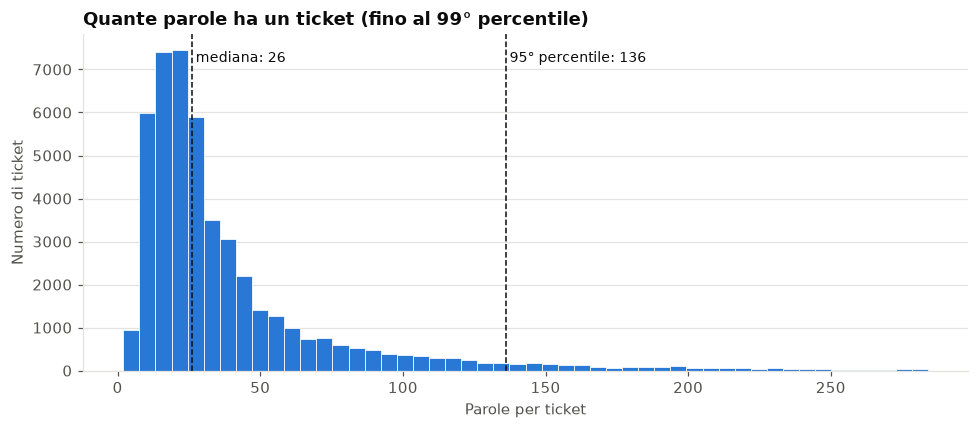

In [10]:
# Istogramma. Escludiamo solo dalla Visualizzazione l'1% dei ticket più lunghi per evitare valori estremi che allungano l'asse e schiacciano tutto a sinistra.
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.loc[df["n_parole"] <= p99, "n_parole"], bins=50, color=COLORE, edgecolor="white", linewidth=0.5)

for valore, nome in [(mediana, "mediana"), (p95, "95° percentile")]:
    ax.axvline(valore, color=TESTO, linestyle="--", linewidth=1)
    ax.text(valore, ax.get_ylim()[1] * 0.95, f" {nome}: {valore:.0f}", fontsize=9, color=TESTO, va="top")

ax.set_title("Quante parole ha un ticket (fino al 99° percentile)")
ax.set_xlabel("Parole per ticket")
ax.set_ylabel("Numero di ticket")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

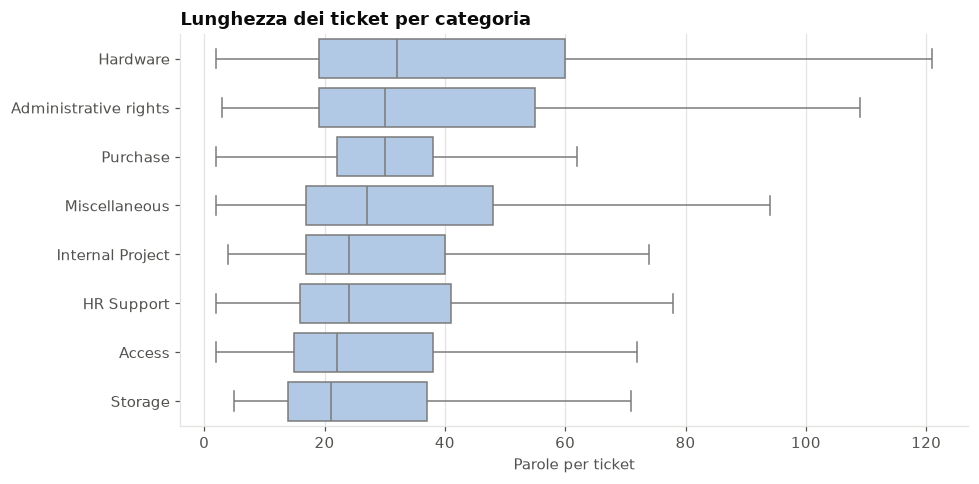

In [11]:
# Boxplot per categoria, ordinate dalla mediana più alta alla più bassa.
# Dal 25° al 75° percentile, la linea interna è la mediana.
ordine_mediana = df.groupby(LABEL_COL)["n_parole"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df, x="n_parole", y=LABEL_COL, order=ordine_mediana, color=COLORE_CHIARO,
             showfliers=False, linewidth=1, ax=ax) # showfliers nasconde i singoli valori estremi per rendere il grafico leggibile
ax.set_title("Lunghezza dei ticket per categoria")
ax.set_xlabel("Parole per ticket")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [12]:
# Ticket molto corti
corti = df[df["n_parole"] <= 2]
print(f"Ticket con 2 parole o meno: {len(corti)} ({len(corti) / len(df) * 100:.2f}%)")
if len(corti) > 0:
    display(corti.sample(min(10, len(corti)), random_state=RANDOM_STATE)[[TEXT_COL, LABEL_COL]])

Ticket con 2 parole o meno: 14 (0.03%)


,Document,Topic_group
29681,installation officer,Purchase
36619,bug bug,Miscellaneous
4215,open si,Hardware
37497,de manager,Hardware
11612,relocate relocate,Hardware
23348,cable tester,Hardware
6450,possible possible,HR Support
4635,account developer,Access
41988,issue issue,Hardware
10596,leaver leaver,HR Support


### Osservazioni (parte 7)
- Per la LSTM una lunghezza massima tra 136-150 parole copre il 95% dei ticket.
- I ticket più lunghi sono appartenenti alla categoria "Hardware" seguita da "Administrative rights" mentre, le categorie "Storage" e "Access" hanno i ticket più corti.
- I ticket con 2 parole o meno sono 14 su 47.837. Abbiamo due opzioni: 1. Possono essere tenuti perché sono pochi e non cambiano nulla, 2. Possono essere tolti almeno quelli che non hanno senso perché sono rumore.

# 8. Vocabolario e parole caratteristiche

### 8.1 In che forma è il testo?
Dalla documentazione del dataset sappiamo che i testi sono **già processati**: tutto minuscolo, senza punteggiature, senza molte *stopword* (parole comuni come 'the', 'and', 'is') e lemmatizzati (parole ridotte alla forma base, es. 'printers' -> 'printer').

Nell'applicazione l'utente scriverà frasi normali e per far funzionare il classificatore dovremo trasformare le sue richieste per renderle come i ticket di addestramento, quindi abbiamo necessità di sapere esattamente in che forma sono.

In [13]:
# .str.contains(espressione_regolare) restituisce True/False per ogni ticket;
# .mean() su True/False dà la quota di True (True vale 1, False vale 0)
quota_maiuscole = testo.str.contains(r"[A-Z]").mean()
quota_cifre = testo.str.contains(r"[0-9]").mean()
quota_punteggiatura = testo.str.contains(r"[^a-zA-Z0-9\s]").mean()

print(f"Ticket con lettere maiuscole: {quota_maiuscole * 100:5.1f}%")
print(f"Ticket con cifre:             {quota_cifre * 100:5.1f}%")
print(f"Ticket con punteggiatura:     {quota_punteggiatura * 100:5.1f}%")

# Quante parole sono stopword inglesi? (lista standard di scikit-learn)
tutte_le_parole = [parola for t in testo for parola in t.split()]
quota_stopword = sum(parola in ENGLISH_STOP_WORDS for parola in tutte_le_parole) / len(tutte_le_parole)
print(f"Parole che sono stopword: {quota_stopword * 100:5.1f}%")

Ticket con lettere maiuscole:   0.0%
Ticket con cifre:               0.0%
Ticket con punteggiatura:       0.0%
Parole che sono stopword:  21.6%


### 8.2 Il vocabolario
Contiamo quante parole diverse esistono, quali sono le più frequenti e quali compaiono una volta sola (potrebbero essere errori di battitura, nomi propri o codici)

In [14]:
frequenze = Counter(tutte_le_parole)
n_rare = sum(1 for conteggo in frequenze.values() if conteggo == 1)

print(f"Parole totali:                {len(tutte_le_parole):,}".replace(",","."))
print(f"Parole diverse (vocabolario)  {len(frequenze):,}".replace(",","."))
print(f"Parole che compaiono 1 volta: {n_rare:,} ({n_rare / len(frequenze) * 100:.0f}% del vocabolario)".replace(",","."))

display(pd.DataFrame(frequenze.most_common(20), columns=["parola", "occorrenze"]))

Parole totali:                2.085.566
Parole diverse (vocabolario)  12.327
Parole che compaiono 1 volta: 2.715 (22% del vocabolario)


,parola,occorrenze
0,please,70212
1,pm,28902
2,hi,28498
3,regards,27212
4,thank,24962
5,for,24456
6,hello,23025
7,you,21828
8,re,21034
9,thanks,19852


### 8.3 Parole caratteristiche per categoria
Vogliamo capire se ogni categoria ha **parole sue**. Se sì, un modello basato sulle parole (come TF-IDF + regressione logistica, il nostro primo modello) avrà buone possibilità di funzionare.

**Perché non contiamo semplicemente le parole più frequenti per categoria?** Le parole comuni a tutti i ticket (es. "please", "issue") comparirebbero in cima a ogni elenco e non ci direbbero nulla.

**Scelta: TF-IDF.** Dà un peso alto a una parola se è frequente **in quel ticket** (TF, *term frequency*) ma rara **nel resto dei ticket** (IDF, *inverse document frequency*). Facendo la media dei pesi sui ticket di una categoria otteniamo le parole che la distinguono.

**Nota importante:** qui calcoliamo il TF-IDF su **tutti** i dati perché stiamo solo osservando. Quando addestreremo il modello, invece, il TF-IDF andrà calcolato **solo sui dati di training**, altrimenti informazioni del test "trapelerebbero" nel modello.

In [16]:
vettorizzatore = TfidfVectorizer(min_df=5)  # ingnora parole presenti in meno di 5 ticket
X = vettorizzatore.fit_transform(testo)
termini = np.array(vettorizzatore.get_feature_names_out())
print(f"Matrice TF-IDF: {X.shape[0]} ticket x {X.shape[1]} parole")

righe = []
for categoria in conteggi.index:
    # True per i ticket di questa categoria, False per tutti gli altri
    maschera = (df[LABEL_COL] == categoria).to_numpy()
    # Peso medio di ogni parola nei ticket di questa categoria
    media_categoria = np.asarray(X[maschera].mean(axis=0)).ravel()
    # Peso medio di ogni parola nei ticket delle altre categorie (~ inverte la maschera: True diventa False e viceversa)
    media_altre = np.asarray(X[~maschera].mean(axis=0)).ravel()
    # Quanto ogni parola è più presente qui che altrove
    differenza = media_categoria - media_altre
    # Argsort ordina dal valore più piccolo al più grande, [::-1] inverte l'ordine, [:10] prende i primi 10
    migliori = termini[differenza.argsort()[::-1][:10]]
    righe.append({"categoria": categoria, "10 parole più caratteristiche": ",".join(migliori)})

display(pd.DataFrame(righe))

Matrice TF-IDF: 47837 ticket x 6353 parole


,categoria,10 parole più caratteristiche
0,Hardware,"monitor,laptop,you,cable,with,meeting,sent,connect,phone,room"
1,HR Support,"starter,form,error,leave,leaver,submit,new,annual,oracle,fill"
2,Access,"confluence,card,user,license,password,account,reset,create,git,users"
3,Miscellaneous,"change,add,approval,name,owner,approve,mailing,groups,list,manager"
4,Storage,"wants,mailbox,folder,decline,accept,shared,access,to,size,storage"
5,Purchase,"po,purchase,administrator,purchased,item,receipts,receive,log,ordered,consideration"
6,Internal Project,"code,project,setup,codes,pas,pipeline,attached,opportunity,create,new"
7,Administrative rights,"upgrade,outlook,issues,windows,install,update,software,with,you,version"


### Osservazioni (parte 8)
**Forma del testo**
- Il testo è tutto minuscolo, senza cifre e senza punteggiatura.
- Le stopword sono state rimosse solo in parte: sono ancora il 21.6% delle parole. Non conoscendo il preprocessing originale, valuterò il modello con e senza la rimozione delle stopword.

**Vocabolario**
- 2.085.566 parole totali, 12.327 parole diverse.
- 2.715 parole (22%) compaiono una sola volta: con 'min_df=5' il vocabolario scende a 6.353 parole.
- Le parole più frequenti non riguardano l'IT: sono saluti, formule di cortesia e intestazioni di mail. I ticket sono mail: queste parole sono rumore per la classificazione e creano una differenza rispetto ai messaggi brevi che gli utenti scriveranno nella chat.

**Parole caratteristiche per categoria (TF-IDF)**
- Categorie ben riconoscibili. In "Hardware" e "Administrative rights" restano parole come "you, with, sent" dovute a ticket più lunghi.

**Implicazioni per i passi successivi**
1. Modello di base sul testo così com'è
2. Esperimenti: senza stopword e senza saluti, intestazioni e giorni (lista personalizzata).
3. Confusioni attese: Hardare <-> Administrative rights, Acces <-> Storage <-> HR Support


# 9. Leggere esempi reali
Leggere i ticket ci permette di capire come scrivono gli utenti e di individuare etichette sbagliate.
Da analisi già pubblicate su questo dataset sappiamo che la categoria `Miscellaneous` contiene diversi ticket che sembrano appartenenti ad altre categorie

In [17]:
for categoria in conteggi.index:
    print(f"\n=== {categoria} ===")
    sottoinsieme = df[df[LABEL_COL] == categoria]
    esempi = sottoinsieme.sample(min(3, len(sottoinsieme)), random_state=RANDOM_STATE)
    for t in esempi[TEXT_COL].fillna(""):
        print(" -", t[:200] + ("..." if len(t) > 200 else ""))


=== Hardware ===
 - monitor request vulcan friday october pm hello please log each user monitor allocation user vulcan thank weekend engineer friday october vulcan parte ne va respective va
 - stopped when docker start was executed sent wednesday february hi we having same problem we had few days ago server was stopped when executed docker start looks like if machine have enough resources d...
 - issue re access through for hello still work attached log error received during installation restarted machine disconnected tethered phone can connect thank you

=== HR Support ===
 - access to new pas friday february hi guys please rights involved level thanks discipline lead
 - new starter bucharest friday pm hello va date administration officer
 - set up new service sn friday pm sn hello please find attached sn form thanks regards

=== Access ===
 - confluence access for wednesday february pm confluence please confluence thanks
 - password reset open access dear can you please help with ri

### Osservazioni (parte 9)
- La maggior parte degli esempi è coerente con la categoria.
- Esempi con etichetta dubbia (rumore nelle etichette):
  - "access to new pas ... rights involved level" → HR Support, ma sembra **Access**
  - "restart ... configure backups for machine" → Miscellaneous, ma sembra **Hardware/Storage**
  - "set up and swap leased for new" → Administrative rights, ma sembra **Hardware**
  - "outlook breaks when switching to cable" → Administrative rights, ma sembra **Hardware**
  - "mailbox problem ... entered credentials" → Storage, ma sembra **Access**
  -> Il modello non potrà raggiungere il 100%: alcuni "errori" saranno etichette sbagliate. Nell'analisi degli errori leggerò i ticket classificati male.
- **Firme e ruoli** di chi scrive (engineer, head, administrator, manager) compaiono nei testi: *administrator* tra le parole tipiche di Purchase
  è una firma, non il contenuto. Rischio che il modello impari "chi scrive" invece di "cosa chiede".
- Il preprocessing originale ha rimosso anche le **negazioni** ("machine have enough resources" invece di "doesn't have"):
  attenzione nell'esperimento sulle stopword.
- Restano tracce delle email: oggetto ripetuto, date, "sent", qualche parola non inglese.
- Alcuni ticket contengono **più problemi** ma hanno una sola categoria: nell'app il chatbot gestirà un problema alla volta.

## 10. Riepilogo

| Aspetto | Valore / osservazione |
|---|---|
| Numero di ticket | 47.837 |
| Valori mancanti / testi vuoti | 0 / 0 |
| Duplicati e conflitti | 0 duplicati esatti, 0 testi con categorie diverse. Probabili **quasi-duplicati** (email standard in Storage e Purchase) da gestire nello split |
| Categoria più grande (%) | Hardware: 13.617 ticket (28,5%) |
| Categoria più piccola (%) | Administrative rights: 1.760 ticket (3,7%) |
| Rapporto di sbilanciamento | 7,7 a 1 → metrica F1 macro, split stratificato, `class_weight="balanced"` |
| Mediana parole per ticket | 26 (metà dei ticket tra 17 e 46 parole; media 43,6 per la coda di ticket lunghi, massimo 981) |
| 95° percentile parole | 136 (99° percentile: 284) → lunghezza massima per la LSTM intorno a 136-150 |
| Ticket cortissimi (≤ 2 parole) | 14 (0,03%), in parte non classificabili: li tengo. Nell'app il chatbot chiederà più dettagli |
| Forma del testo | Minuscolo, senza cifre né punteggiatura; stopword rimosse solo in parte (21,6%), negazioni comprese. Vocabolario di 12.327 parole (6.353 con `min_df=5`). Molti saluti, intestazioni e firme delle email |
| Problemi notati nelle etichette | Rumore nelle etichette (es. richieste di accesso in HR Support e Storage, problemi hardware in Administrative rights); Miscellaneous vicina ad Access; firme che possono creare falsi indizi (es. *administrator* in Purchase) |